<a href="https://colab.research.google.com/github/Nihalht/quamtum-lab-pr/blob/main/5_Deutsch_Jozsa_Algorithm_Oracle_Concept.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab Experiment 5: Deutsch-Jozsa Algorithm: Oracle Concept and Circuit Construction

The Deutsch-Jozsa algorithm determines whether a given function (oracle) is constant (returns the same value for all inputs) or balanced (returns 0 for half of the inputs, and 1 for the other half) in just one query.

In this notebook, we focus on building the Oracle circuits and the main Deutsch-Jozsa circuit frame.

In [1]:
!pip install qiskit pylatexenc

import numpy as np
from qiskit import QuantumCircuit
import matplotlib.pyplot as plt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 19.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 20.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [qiskit]


## 1. Creating a Constant Oracle

A constant oracle always returns 0 or 1. Let's make one that returns 1 (by applying an X gate to the output qubit).

Constant Oracle (n=3):


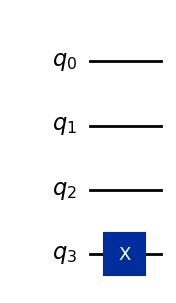

In [2]:
def get_constant_oracle(n):
    oracle_qc = QuantumCircuit(n+1)

    # Randomly decide to return 0 or 1
    output = np.random.randint(2)
    if output == 1:
        oracle_qc.x(n)

    return oracle_qc

print("Constant Oracle (n=3):")
const_oracle = get_constant_oracle(3)
const_oracle.draw('mpl')

## 2. Creating a Balanced Oracle

A balanced oracle returns 0 for half of inputs and 1 for the other half. We can create this by applying CNOTs with each input qubit as control and the output qubit as target, occasionally wrapping the controls in X gates.

Balanced Oracle (n=3):


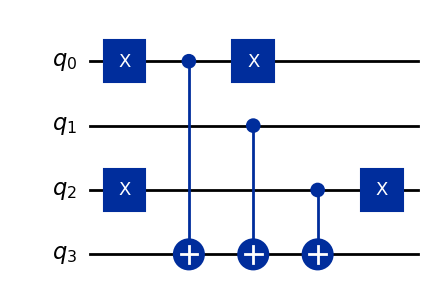

In [3]:
def get_balanced_oracle(n):
    oracle_qc = QuantumCircuit(n+1)

    # Apply X gates to some random qubits
    b_str = "101" # Example string for n=3

    for qubit in range(len(b_str)):
        if b_str[qubit] == '1':
            oracle_qc.x(qubit)

    # Apply CNOTs
    for qubit in range(n):
        oracle_qc.cx(qubit, n)

    # Apply X gates back
    for qubit in range(len(b_str)):
        if b_str[qubit] == '1':
            oracle_qc.x(qubit)

    return oracle_qc

print("Balanced Oracle (n=3):")
bal_oracle = get_balanced_oracle(3)
bal_oracle.draw('mpl')

## 3. Constructing the Full Deutsch-Jozsa Circuit

Full Deutsch-Jozsa Circuit with Balanced Oracle:


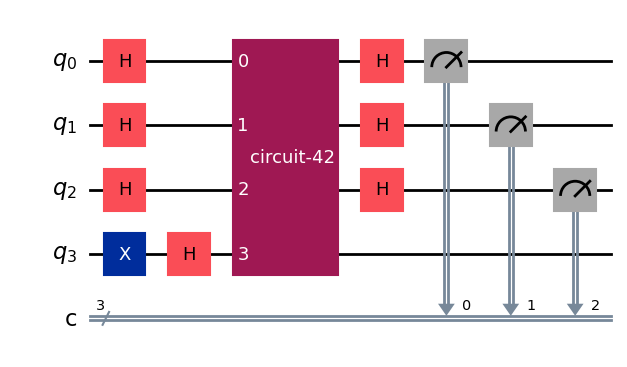

In [4]:
def dj_algorithm(oracle, n):
    dj_circuit = QuantumCircuit(n+1, n)

    # Initialize output qubit to |1>
    dj_circuit.x(n)

    # Apply H-gates to all qubits
    for qubit in range(n+1):
        dj_circuit.h(qubit)

    # Append oracle
    dj_circuit.append(oracle, range(n+1))

    # Apply H-gates to input qubits
    for qubit in range(n):
        dj_circuit.h(qubit)

    # Measure input qubits
    for i in range(n):
        dj_circuit.measure(i, i)

    return dj_circuit

print("Full Deutsch-Jozsa Circuit with Balanced Oracle:")
dj_circuit = dj_algorithm(bal_oracle, 3)
dj_circuit.draw('mpl')

## 4. Running the Circuit and Visualizing the Results

We will now run the constructed Deutsch-Jozsa circuit on the `Sampler` simulator to obtain the measurement counts and plot them using a histogram.

Measurement counts: {'111': 1024}


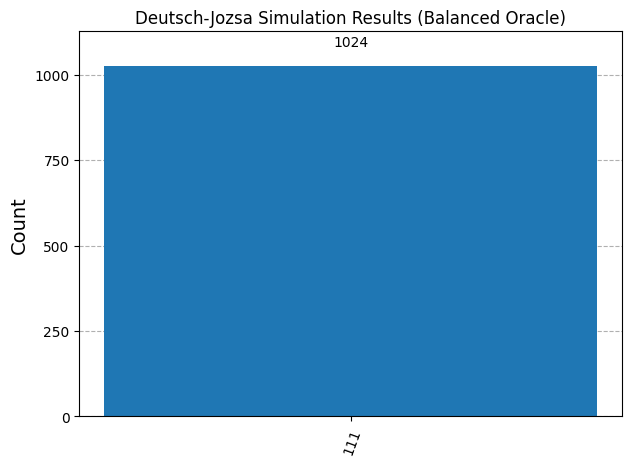

In [5]:
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram

# 1. Transpile/Prepare the circuit for simulation
# (We already have 'dj_circuit' containing the 3-qubit balanced oracle)

# 2. Use StatevectorSampler to run the circuit
sampler = StatevectorSampler()
job = sampler.run([dj_circuit])
result = job.result()

# 3. Retrieve results from the first pub (Parameterized Utility Block)
pub_result = result[0]
counts = pub_result.data.c.get_counts()

print("Measurement counts:", counts)

# 4. Plot the histogram of the results
fig, ax = plt.subplots(figsize=(7, 5))
plot_histogram(counts, ax=ax)
plt.title("Deutsch-Jozsa Simulation Results (Balanced Oracle)")
plt.show()

### Explanation of the Output:
Since we used a **balanced oracle**, the input state $|000\rangle$ is transformed. Under the Deutsch-Jozsa algorithm, we should measure a state **other than** `000` with 100% probability. If the oracle had been constant, we would have measured `000` with 100% probability.

## 5. Experiment with an Unbalanced Oracle

The Deutsch-Jozsa algorithm assumes a strict promise that the oracle is either **constant** (0% or 100% ones) or **balanced** (exactly 50% ones). Let's see what happens if we break this promise using an **unbalanced oracle** (e.g., one that returns `1` for only one of the input combinations, and `0` for all others).

Unbalanced Oracle (returns 1 only for |111>):


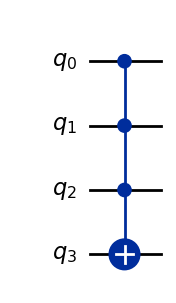

In [6]:
def get_unbalanced_oracle(n):
    # This oracle will flip the output qubit state only if the input is |111>
    oracle_qc = QuantumCircuit(n+1)

    # Multi-controlled Toffoli (MCX) gate targeting the output qubit (n)
    oracle_qc.mcx(list(range(n)), n)

    return oracle_qc

print("Unbalanced Oracle (returns 1 only for |111>):")
unbal_oracle = get_unbalanced_oracle(3)
unbal_oracle.draw('mpl')

Unbalanced Oracle Measurement counts: {'101': 66, '000': 568, '001': 64, '100': 78, '110': 66, '011': 53, '010': 61, '111': 68}


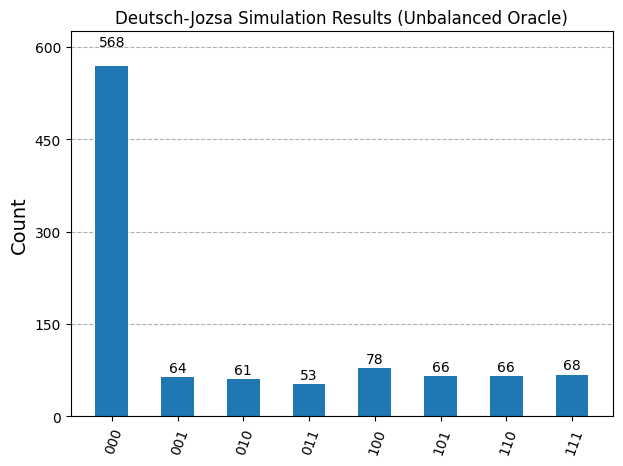

In [7]:
# Construct the full DJ circuit using our unbalanced oracle
dj_circuit_unbalanced = dj_algorithm(unbal_oracle, 3)

# Run simulation
job_unbal = sampler.run([dj_circuit_unbalanced])
result_unbal = job_unbal.result()
counts_unbal = result_unbal[0].data.c.get_counts()

print("Unbalanced Oracle Measurement counts:", counts_unbal)

# Plot the distribution
fig, ax = plt.subplots(figsize=(7, 5))
plot_histogram(counts_unbal, ax=ax)
plt.title("Deutsch-Jozsa Simulation Results (Unbalanced Oracle)")
plt.show()

### Observation:
As you can see, when the promise is broken, we get a **mixture of outcomes**. We measure `000` (which typically indicates a constant function) with some probability, and other non-zero states (which typically indicate a balanced function) with other probabilities. Thus, the deterministic guarantee of the Deutsch-Jozsa algorithm no longer holds.